# EfficientNetV2-S Transfer Learning Baseline

EfficientNetV2-S pretrained on ImageNet is evaluated as the second transfer-learning baseline for the cleaned skin-disease dataset. The same split and training methodology used for ResNet50 are retained wherever possible so that validation generalization can be compared under a controlled protocol. The change from 224 x 224 to 384 x 384 input means this is a comparison of pretrained model pipelines rather than a pure architecture-only ablation. Model fitting, early stopping, and checkpoint selection use only the training and validation subsets. The test subset remains completely untouched.

## 1. Imports and Reproducibility Configuration

In [1]:
from pathlib import Path
import os
import random
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from PIL import Image, ImageOps
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
import torch
import torchvision
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import EfficientNet_V2_S_Weights, efficientnet_v2_s
from tqdm.auto import tqdm

RANDOM_SEED = 42


def set_reproducible_seed(seed: int) -> None:
    """Configure deterministic random states for Python, NumPy, and PyTorch."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    torch.use_deterministic_algorithms(True, warn_only=True)


set_reproducible_seed(RANDOM_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CUDA_AVAILABLE = torch.cuda.is_available()
GPU_NAME = torch.cuda.get_device_name(0) if CUDA_AVAILABLE else "Not available"
GPU_MEMORY_GB = (
    torch.cuda.get_device_properties(0).total_memory / 1024**3
    if CUDA_AVAILABLE
    else 0.0
)

print(f"PyTorch version: {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")
print(f"CUDA available: {CUDA_AVAILABLE}")
print(f"PyTorch CUDA version: {torch.version.cuda}")
print(f"Selected device: {DEVICE}")
print(f"GPU name: {GPU_NAME}")
print(
    f"Total GPU memory: {GPU_MEMORY_GB:.2f} GB"
    if CUDA_AVAILABLE
    else "Total GPU memory: Not available"
)

PyTorch version: 2.13.0+cu132
torchvision version: 0.28.0+cu132
CUDA available: True
PyTorch CUDA version: 13.2
Selected device: cuda
GPU name: NVIDIA GeForce RTX 3060 Laptop GPU
Total GPU memory: 6.00 GB


## 2. Project Paths

In [2]:
RAW_RELATIVE_PATH = Path("data/raw/skin-diseases-image-dataset/IMG_CLASSES")


def find_project_root(start: Path) -> Path:
    """Find the nearest parent containing the raw dataset and processed manifests."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (
            (candidate / RAW_RELATIVE_PATH).is_dir()
            and (candidate / "data" / "processed").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root containing the raw dataset and data/processed."
    )


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DATA_DIR = PROJECT_ROOT / RAW_RELATIVE_PATH
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = PROJECT_ROOT / "models"
TORCH_CACHE_DIR = MODELS_DIR / "torch_cache"

for directory in [REPORTS_DIR, FIGURES_DIR, MODELS_DIR, TORCH_CACHE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

torch.hub.set_dir(str(TORCH_CACHE_DIR))

MANIFEST_PATHS = {
    "train": PROCESSED_DIR / "train.csv",
    "validation": PROCESSED_DIR / "validation.csv",
    "test": PROCESSED_DIR / "test.csv",
}
missing_manifests = [path for path in MANIFEST_PATHS.values() if not path.is_file()]
if missing_manifests:
    missing_text = "\n".join(f"  - {path}" for path in missing_manifests)
    raise FileNotFoundError(
        "Processed manifests are missing. Execute "
        "notebooks/02_dataset_cleaning_and_split.ipynb first. Missing files:\n"
        f"{missing_text}"
    )

CHECKPOINT_PATH = MODELS_DIR / "efficientnetv2_s_baseline_best.pth"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw dataset: {RAW_DATA_DIR}")
print(f"Model checkpoint: {CHECKPOINT_PATH}")

Project root: C:\Projekt konferencyjny Turcja\skin-disease-classification
Raw dataset: C:\Projekt konferencyjny Turcja\skin-disease-classification\data\raw\skin-diseases-image-dataset\IMG_CLASSES
Model checkpoint: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\efficientnetv2_s_baseline_best.pth


## 3. Load and Validate Data Manifests

The split created in the preceding stage is loaded without reshuffling or reassigning any image. The test manifest is validated structurally but is not used to create a prediction loader.

In [3]:
manifests = {
    split_name: pd.read_csv(path)
    for split_name, path in MANIFEST_PATHS.items()
}
REQUIRED_COLUMNS = {"relative_path", "class_name", "class_id", "group_id"}

for split_name, manifest in manifests.items():
    missing_columns = REQUIRED_COLUMNS - set(manifest.columns)
    if missing_columns:
        raise ValueError(
            f"{MANIFEST_PATHS[split_name].name} is missing columns: {sorted(missing_columns)}"
        )
    if manifest["relative_path"].duplicated().any():
        raise ValueError(f"Duplicate paths exist within the {split_name} manifest.")
    if "split" in manifest.columns and not manifest["split"].eq(split_name).all():
        raise ValueError(f"The split column is inconsistent in {MANIFEST_PATHS[split_name].name}.")

all_paths = pd.concat(
    [
        manifest[["relative_path"]].assign(source_split=split_name)
        for split_name, manifest in manifests.items()
    ],
    ignore_index=True,
)
if all_paths["relative_path"].duplicated().any():
    duplicated_paths = all_paths.loc[
        all_paths["relative_path"].duplicated(keep=False), "relative_path"
    ]
    raise ValueError(
        f"{duplicated_paths.nunique():,} image path(s) occur in more than one split."
    )

missing_images = [
    relative_path
    for relative_path in all_paths["relative_path"]
    if not (PROJECT_ROOT / relative_path).is_file()
]
if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images):,} manifest image paths do not exist on disk."
    )

split_summary = pd.DataFrame(
    {
        "split": list(manifests),
        "images": [len(manifests[name]) for name in manifests],
    }
)
split_summary["percentage"] = 100 * split_summary["images"] / split_summary["images"].sum()
display(split_summary)

train_validation_distribution = pd.concat(
    [
        manifest.groupby(["class_id", "class_name"]).size().rename("images").reset_index().assign(split=split_name)
        for split_name, manifest in manifests.items()
        if split_name in {"train", "validation"}
    ],
    ignore_index=True,
)
train_validation_distribution["percentage_within_split"] = (
    100
    * train_validation_distribution["images"]
    / train_validation_distribution.groupby("split")["images"].transform("sum")
)
display(
    train_validation_distribution.sort_values(["class_id", "split"])
)

print(f"Training images: {len(manifests['train']):,}")
print(f"Validation images: {len(manifests['validation']):,}")
print(f"Frozen test images (structural validation only): {len(manifests['test']):,}")
print(f"Unique paths across all splits: {all_paths['relative_path'].nunique():,}")

,split,images,percentage
0,train,18491,70.009844
1,validation,3961,14.996971
2,test,3960,14.993185


,class_id,class_name,images,split,percentage_within_split
0,0,Eczema,1068,train,5.775783
10,0,Eczema,228,validation,5.756122
1,1,Melanoma,2195,train,11.870640
11,1,Melanoma,471,validation,11.890937
2,2,Atopic Dermatitis,804,train,4.348061
12,2,Atopic Dermatitis,171,validation,4.317092
3,3,Basal Cell Carcinoma (BCC),2323,train,12.562868
13,3,Basal Cell Carcinoma (BCC),497,validation,12.547337
4,4,Melanocytic Nevi (NV),5577,train,30.160619
14,4,Melanocytic Nevi (NV),1195,validation,30.169149


Training images: 18,491
Validation images: 3,961
Frozen test images (structural validation only): 3,960
Unique paths across all splits: 26,412


## 4. Class Mapping

Labels are read from manifest columns rather than inferred from directory ordering.

In [4]:
mapping_frames = []
for split_name, manifest in manifests.items():
    split_mapping = manifest[["class_id", "class_name"]].drop_duplicates()
    if split_mapping["class_id"].duplicated().any() or split_mapping["class_name"].duplicated().any():
        raise ValueError(f"The class mapping is not one-to-one in the {split_name} manifest.")
    mapping_frames.append(split_mapping.assign(split=split_name))

mapping_check = pd.concat(mapping_frames, ignore_index=True)
class_mapping_table = (
    mapping_check[["class_id", "class_name"]]
    .drop_duplicates()
    .sort_values("class_id", ignore_index=True)
)
if mapping_check.groupby("split").size().nunique() != 1:
    raise ValueError("The manifests do not contain the same number of classes.")
if class_mapping_table["class_id"].tolist() != list(range(len(class_mapping_table))):
    raise ValueError("Class IDs are not contiguous from zero.")
for split_name, split_mapping in mapping_check.groupby("split"):
    observed = split_mapping[["class_id", "class_name"]].sort_values("class_id").reset_index(drop=True)
    if not observed.equals(class_mapping_table):
        raise ValueError(f"Class mapping differs in the {split_name} manifest.")

CLASS_ID_TO_NAME = dict(
    zip(class_mapping_table["class_id"], class_mapping_table["class_name"])
)
NUM_CLASSES = len(CLASS_ID_TO_NAME)
display(class_mapping_table)
print(f"Number of classes: {NUM_CLASSES}")

,class_id,class_name
0,0,Eczema
1,1,Melanoma
2,2,Atopic Dermatitis
3,3,Basal Cell Carcinoma (BCC)
4,4,Melanocytic Nevi (NV)
5,5,Benign Keratosis-like Lesions (BKL)
6,6,Psoriasis / Lichen Planus / Related Diseases
7,7,Seborrheic Keratoses / Other Benign Tumors
8,8,Tinea / Ringworm / Candidiasis / Other Fungal ...
9,9,Warts / Molluscum / Other Viral Infections


Number of classes: 10


## 5. Input Preprocessing

EfficientNetV2-S receives 384 x 384 inputs with ImageNet normalization. Training augmentation follows the moderate ResNet50 protocol: conservative random cropping, horizontal reflection, small rotation, and mild color jitter. The deterministic validation pipeline uses the resize and center-crop geometry associated with the pretrained weights. Raw image files are never altered or saved.

In [5]:
IMAGE_SIZE = 384
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
PRETRAINED_WEIGHTS = EfficientNet_V2_S_Weights.DEFAULT

train_transform = transforms.Compose(
    [
        transforms.RandomResizedCrop(
            IMAGE_SIZE,
            scale=(0.80, 1.00),
            ratio=(0.90, 1.10),
        ),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10,
            saturation=0.10,
            hue=0.02,
        ),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ]
)

validation_transform = PRETRAINED_WEIGHTS.transforms()
if tuple(validation_transform.crop_size) not in {
    (IMAGE_SIZE,),
    (IMAGE_SIZE, IMAGE_SIZE),
}:
    raise ValueError(
        "The pretrained EfficientNetV2-S validation transform does not produce "
        f"{IMAGE_SIZE} x {IMAGE_SIZE} inputs."
    )
if not (
    np.allclose(validation_transform.mean, IMAGENET_MEAN)
    and np.allclose(validation_transform.std, IMAGENET_STD)
):
    raise ValueError("The pretrained validation transform uses unexpected normalization.")

## 6. Dataset and DataLoaders

In [6]:
class SkinDiseaseDataset(Dataset):
    """Load images and labels directly from a processed manifest."""

    def __init__(self, manifest: pd.DataFrame, project_root: Path, transform=None):
        self.manifest = manifest.reset_index(drop=True).copy()
        self.project_root = project_root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.manifest)

    def __getitem__(self, index: int):
        row = self.manifest.iloc[index]
        image_path = self.project_root / row["relative_path"]
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            if self.transform is not None:
                image = self.transform(image)
        return image, int(row["class_id"]), row["relative_path"]


train_dataset = SkinDiseaseDataset(
    manifests["train"], PROJECT_ROOT, transform=train_transform
)
validation_dataset = SkinDiseaseDataset(
    manifests["validation"], PROJECT_ROOT, transform=validation_transform
)

BATCH_SIZE = 8
NUM_WORKERS = 0  # Safe for Windows and interactive Jupyter execution.
PIN_MEMORY = CUDA_AVAILABLE

# If CUDA reports an out-of-memory error, stop and reduce BATCH_SIZE explicitly.
train_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    generator=train_generator,
    persistent_workers=NUM_WORKERS > 0,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
)

print(f"Training batches: {len(train_loader):,}")
print(f"Validation batches: {len(validation_loader):,}")
print(f"Batch size: {BATCH_SIZE}")
print(f"DataLoader workers: {NUM_WORKERS}")
print(f"Pinned memory: {PIN_MEMORY}")

Training batches: 2,312
Validation batches: 496
Batch size: 8
DataLoader workers: 0
Pinned memory: True


## 7. Data Sanity Check

A small transformed batch verifies image loading, labels, normalization reversal, and augmentation behavior. The display is not used for medical interpretation.

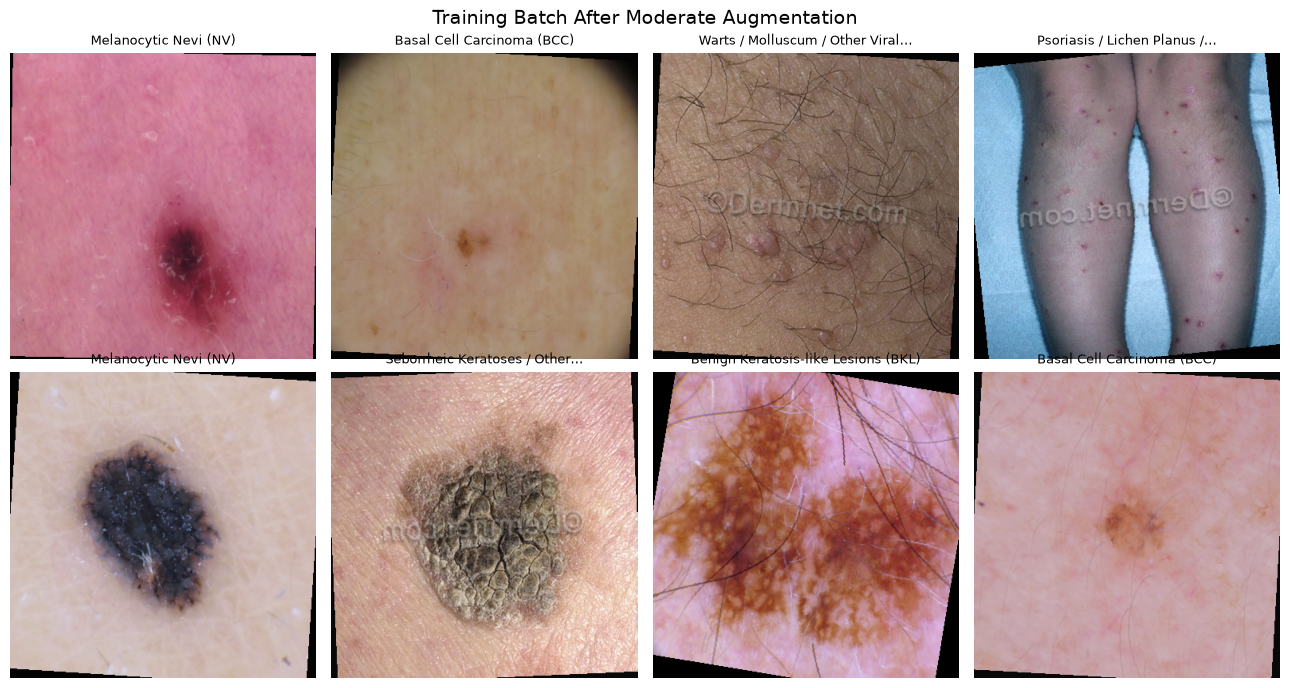

In [7]:
sample_images, sample_labels, _ = next(iter(train_loader))
train_generator.manual_seed(RANDOM_SEED)

mean_tensor = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(IMAGENET_STD).view(3, 1, 1)
display_count = min(8, len(sample_images))

fig, axes = plt.subplots(2, 4, figsize=(13, 7), squeeze=False)
for axis, image_tensor, label in zip(
    axes.flat, sample_images[:display_count], sample_labels[:display_count]
):
    image_for_display = (image_tensor.cpu() * std_tensor + mean_tensor).clamp(0, 1)
    axis.imshow(image_for_display.permute(1, 2, 0).numpy())
    axis.set_title(
        textwrap.shorten(CLASS_ID_TO_NAME[int(label)], width=35, placeholder="…"),
        fontsize=9,
    )
    axis.axis("off")
for axis in axes.flat[display_count:]:
    axis.axis("off")
fig.suptitle("Training Batch After Moderate Augmentation", fontsize=14)
fig.tight_layout()
plt.show()

## 8. EfficientNetV2-S Model and Baseline Configuration

Default ImageNet weights are loaded through the current torchvision weights API. The final linear layer in the EfficientNet classifier is replaced for the manifest-derived number of classes.

In [8]:
model = efficientnet_v2_s(weights=PRETRAINED_WEIGHTS)
model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, NUM_CLASSES)
model = model.to(DEVICE)

total_parameters = sum(parameter.numel() for parameter in model.parameters())
initial_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)

WARMUP_EPOCHS = 3
FINE_TUNE_MAX_EPOCHS = 18
WARMUP_LEARNING_RATE = 1e-3
FINE_TUNE_LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
EARLY_STOPPING_PATIENCE = 5
CHECKPOINT_CRITERION = "validation_macro_f1"

TRAINING_CONFIGURATION = {
    "random_seed": RANDOM_SEED,
    "architecture": "EfficientNetV2-S",
    "pretrained_weights": PRETRAINED_WEIGHTS.name,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "optimizer": "AdamW",
    "warmup_learning_rate": WARMUP_LEARNING_RATE,
    "fine_tune_learning_rate": FINE_TUNE_LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "warmup_epochs": WARMUP_EPOCHS,
    "fine_tune_max_epochs": FINE_TUNE_MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "checkpoint_criterion": CHECKPOINT_CRITERION,
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "cuda_version": torch.version.cuda,
    "gpu_name": GPU_NAME,
}

print(f"Pretrained weights: {PRETRAINED_WEIGHTS.name}")
print(f"Output classes: {NUM_CLASSES}")
print(f"Total parameters: {total_parameters:,}")
print(f"Initially trainable parameters: {initial_trainable_parameters:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to C:\Projekt konferencyjny Turcja\skin-disease-classification\models\torch_cache\checkpoints\efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [01:04<00:00, 1.34MB/s]


Pretrained weights: IMAGENET1K_V1
Output classes: 10
Total parameters: 20,190,298
Initially trainable parameters: 20,190,298


## 9. Training and Validation Functions

Cross-entropy loss is used without class weighting to preserve a simple primary baseline. CUDA automatic mixed precision is enabled when available. Validation macro F1 is the checkpoint and early-stopping criterion.

In [9]:
criterion = nn.CrossEntropyLoss()
AMP_ENABLED = DEVICE.type == "cuda"


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device,
    freeze_backbone: bool,
):
    """Train for one epoch and return sample-weighted loss and accuracy."""
    model.train()
    if freeze_backbone:
        # Keep frozen feature modules, including BatchNorm layers, in evaluation mode.
        for module in list(model.children())[:-1]:
            module.eval()

    running_loss = 0.0
    correct_predictions = 0
    sample_count = 0

    progress = tqdm(loader, desc="Training", unit="batch", leave=False)
    for images, labels, _ in progress:
        try:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory. Stop this run, reduce BATCH_SIZE below 8, "
                "restart the kernel, and rerun the notebook from the beginning."
            ) from error

        batch_size = labels.size(0)
        running_loss += loss.detach().item() * batch_size
        correct_predictions += (logits.detach().argmax(dim=1) == labels).sum().item()
        sample_count += batch_size
        progress.set_postfix(
            loss=f"{running_loss / sample_count:.4f}",
            accuracy=f"{correct_predictions / sample_count:.3f}",
        )

    return {
        "loss": running_loss / sample_count,
        "accuracy": correct_predictions / sample_count,
    }


@torch.inference_mode()
def evaluate_model(model, loader, criterion, device, description="Validation"):
    """Evaluate a model and return aggregate metrics plus CPU prediction arrays."""
    model.eval()
    running_loss = 0.0
    sample_count = 0
    targets = []
    predictions = []
    confidences = []
    relative_paths = []

    progress = tqdm(loader, desc=description, unit="batch", leave=False)
    for images, labels, paths in progress:
        try:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=AMP_ENABLED,
            ):
                logits = model(images)
                loss = criterion(logits, labels)
        except torch.OutOfMemoryError as error:
            raise RuntimeError(
                "CUDA ran out of memory. Stop this run, reduce BATCH_SIZE below 8, "
                "restart the kernel, and rerun the notebook from the beginning."
            ) from error

        probabilities = torch.softmax(logits.float(), dim=1)
        confidence, predicted = probabilities.max(dim=1)
        batch_size = labels.size(0)
        running_loss += loss.item() * batch_size
        sample_count += batch_size
        targets.extend(labels.cpu().numpy().tolist())
        predictions.extend(predicted.cpu().numpy().tolist())
        confidences.extend(confidence.cpu().numpy().tolist())
        relative_paths.extend(paths)

    targets = np.asarray(targets, dtype=np.int64)
    predictions = np.asarray(predictions, dtype=np.int64)
    confidences = np.asarray(confidences, dtype=np.float32)

    return {
        "loss": running_loss / sample_count,
        "accuracy": accuracy_score(targets, predictions),
        "balanced_accuracy": balanced_accuracy_score(targets, predictions),
        "macro_f1": f1_score(targets, predictions, average="macro", zero_division=0),
        "targets": targets,
        "predictions": predictions,
        "confidences": confidences,
        "relative_paths": relative_paths,
    }


def save_best_checkpoint(
    path: Path,
    model,
    epoch: int,
    stage: str,
    validation_metrics: dict,
):
    """Save a validation-selected checkpoint with reproducibility metadata."""
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "class_mapping": CLASS_ID_TO_NAME,
            "best_validation_macro_f1": validation_metrics["macro_f1"],
            "validation_accuracy": validation_metrics["accuracy"],
            "validation_balanced_accuracy": validation_metrics["balanced_accuracy"],
            "epoch": epoch,
            "stage": stage,
            "training_configuration": TRAINING_CONFIGURATION,
        },
        path,
    )


def load_model_checkpoint(path: Path, model, device):
    """Load a saved checkpoint and restore model parameters on the selected device."""
    checkpoint = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.to(device)
    model.eval()
    return checkpoint


def record_epoch(
    history,
    epoch: int,
    stage: str,
    training_metrics: dict,
    validation_metrics: dict,
    learning_rate: float,
):
    history.append(
        {
            "epoch": epoch,
            "stage": stage,
            "train_loss": training_metrics["loss"],
            "train_accuracy": training_metrics["accuracy"],
            "val_loss": validation_metrics["loss"],
            "val_accuracy": validation_metrics["accuracy"],
            "val_balanced_accuracy": validation_metrics["balanced_accuracy"],
            "val_macro_f1": validation_metrics["macro_f1"],
            "learning_rate": learning_rate,
        }
    )
    pd.DataFrame(history).to_csv(
        REPORTS_DIR / "04_efficientnetv2_training_history.csv",
        index=False,
        encoding="utf-8",
    )

## 10. Two-Stage Transfer Learning

Stage 1 freezes the pretrained backbone for three classifier warm-up epochs. Stage 2 unfreezes the complete network and applies lower-rate fine-tuning for at most 18 epochs. Early stopping during fine-tuning uses validation macro F1 with patience five. No validation or test class weights are introduced.

In [10]:
history = []
best_validation_macro_f1 = -np.inf
best_epoch = None
best_stage = None
global_epoch = 0

# Stage 1: classifier warm-up.
for parameter in model.parameters():
    parameter.requires_grad = False
for parameter in model.classifier[-1].parameters():
    parameter.requires_grad = True

warmup_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 1 trainable parameters: {warmup_trainable_parameters:,}")

warmup_optimizer = AdamW(
    model.classifier[-1].parameters(),
    lr=WARMUP_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
warmup_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)

for stage_epoch in range(1, WARMUP_EPOCHS + 1):
    global_epoch += 1
    print(f"Stage 1/2 — classifier warm-up epoch {stage_epoch}/{WARMUP_EPOCHS}")
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        warmup_optimizer,
        warmup_scaler,
        DEVICE,
        freeze_backbone=True,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    learning_rate = warmup_optimizer.param_groups[0]["lr"]
    record_epoch(
        history,
        global_epoch,
        "classifier_warmup",
        training_metrics,
        validation_metrics,
        learning_rate,
    )

    if validation_metrics["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_metrics["macro_f1"]
        best_epoch = global_epoch
        best_stage = "classifier_warmup"
        save_best_checkpoint(
            CHECKPOINT_PATH,
            model,
            global_epoch,
            best_stage,
            validation_metrics,
        )

    print(
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}"
    )

# Stage 2: full-network fine-tuning.
for parameter in model.parameters():
    parameter.requires_grad = True

fine_tune_trainable_parameters = sum(
    parameter.numel() for parameter in model.parameters() if parameter.requires_grad
)
print(f"Stage 2 trainable parameters: {fine_tune_trainable_parameters:,}")

fine_tune_optimizer = AdamW(
    model.parameters(),
    lr=FINE_TUNE_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)
fine_tune_scheduler = ReduceLROnPlateau(
    fine_tune_optimizer,
    mode="max",
    factor=0.3,
    patience=2,
    min_lr=1e-6,
)
fine_tune_scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
epochs_without_improvement = 0

for stage_epoch in range(1, FINE_TUNE_MAX_EPOCHS + 1):
    global_epoch += 1
    print(f"Stage 2/2 — full fine-tuning epoch {stage_epoch}/{FINE_TUNE_MAX_EPOCHS}")
    training_metrics = train_one_epoch(
        model,
        train_loader,
        criterion,
        fine_tune_optimizer,
        fine_tune_scaler,
        DEVICE,
        freeze_backbone=False,
    )
    validation_metrics = evaluate_model(
        model, validation_loader, criterion, DEVICE
    )
    learning_rate = fine_tune_optimizer.param_groups[0]["lr"]
    record_epoch(
        history,
        global_epoch,
        "full_fine_tuning",
        training_metrics,
        validation_metrics,
        learning_rate,
    )
    fine_tune_scheduler.step(validation_metrics["macro_f1"])

    if validation_metrics["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_metrics["macro_f1"]
        best_epoch = global_epoch
        best_stage = "full_fine_tuning"
        epochs_without_improvement = 0
        save_best_checkpoint(
            CHECKPOINT_PATH,
            model,
            global_epoch,
            best_stage,
            validation_metrics,
        )
        improvement_note = "checkpoint updated"
    else:
        epochs_without_improvement += 1
        improvement_note = (
            f"no macro-F1 improvement for {epochs_without_improvement} epoch(s)"
        )

    print(
        f"train loss={training_metrics['loss']:.4f}, "
        f"train accuracy={training_metrics['accuracy']:.4f}, "
        f"val loss={validation_metrics['loss']:.4f}, "
        f"val accuracy={validation_metrics['accuracy']:.4f}, "
        f"val macro F1={validation_metrics['macro_f1']:.4f}; "
        f"{improvement_note}"
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print(
            "Early stopping activated after "
            f"{EARLY_STOPPING_PATIENCE} fine-tuning epochs without improvement."
        )
        break

training_history = pd.DataFrame(history)
training_history.to_csv(
    REPORTS_DIR / "04_efficientnetv2_training_history.csv",
    index=False,
    encoding="utf-8",
)
display(training_history)
print(f"Best validation macro F1: {best_validation_macro_f1:.4f}")
print(f"Best epoch: {best_epoch} ({best_stage})")
print(f"Checkpoint saved to: {CHECKPOINT_PATH}")

Stage 1 trainable parameters: 12,810
Stage 1/2 — classifier warm-up epoch 1/3


Training:   0%|          | 0/2312 [00:00<?, ?batch/s]

Validation:   0%|          | 0/496 [00:00<?, ?batch/s]

train loss=0.9942, train accuracy=0.6317, val loss=0.8299, val accuracy=0.6948, val macro F1=0.5950
Stage 1/2 — classifier warm-up epoch 2/3


Training:   0%|          | 0/2312 [00:00<?, ?batch/s]

...

Training:   0%|          | 0/2312 [00:00<?, ?batch/s]

Validation:   0%|          | 0/496 [00:00<?, ?batch/s]

train loss=0.0200, train accuracy=0.9936, val loss=0.6114, val accuracy=0.8801, val macro F1=0.8149; no macro-F1 improvement for 1 epoch(s)


,epoch,stage,train_loss,train_accuracy,val_loss,val_accuracy,val_balanced_accuracy,val_macro_f1,learning_rate
0,1,classifier_warmup,0.994228,0.631659,0.829854,0.694774,0.590564,0.594969,0.00100
1,2,classifier_warmup,0.816128,0.697529,0.773168,0.712951,0.613571,0.615597,0.00100
2,3,classifier_warmup,0.771077,0.708507,0.747462,0.723050,0.622490,0.625274,0.00100
3,4,full_fine_tuning,0.782003,0.707912,0.531193,0.806362,0.715007,0.715329,0.00010
4,5,full_fine_tuning,0.540199,0.801309,0.446715,0.835900,0.754858,0.754536,0.00010
5,6,full_fine_tuning,0.428819,0.847493,0.424026,0.850038,0.778312,0.778748,0.00010
6,7,full_fine_tuning,0.351372,0.873939,0.472339,0.845998,0.781169,0.774809,0.00010
7,8,full_fine_tuning,0.286198,0.896382,0.427587,0.864176,0.801955,0.799636,0.00010
8,9,full_fine_tuning,0.235873,0.916230,0.473860,0.858622,0.797486,0.791233,0.00010
9,10,full_fine_tuning,0.194304,0.931859,0.455522,0.870235,0.810563,0.806079,0.00010


Best validation macro F1: 0.8319
Best epoch: 20 (full_fine_tuning)
Checkpoint saved to: C:\Projekt konferencyjny Turcja\skin-disease-classification\models\efficientnetv2_s_baseline_best.pth


## 11. Training Curves

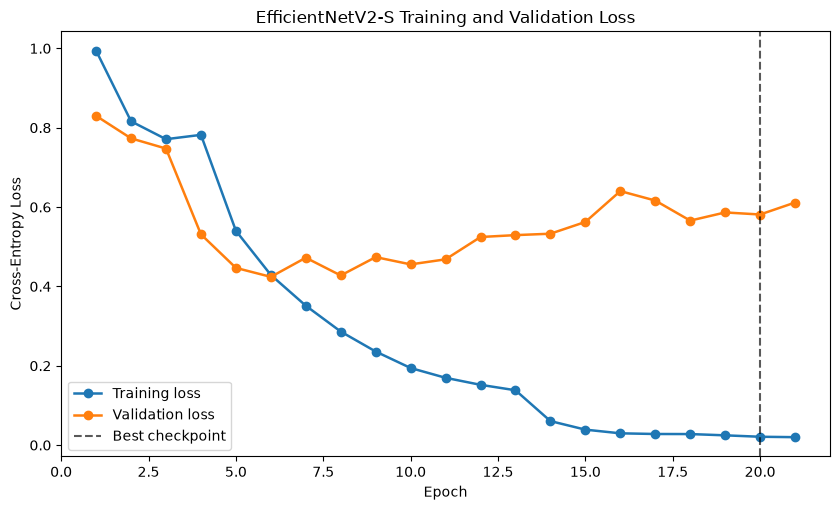

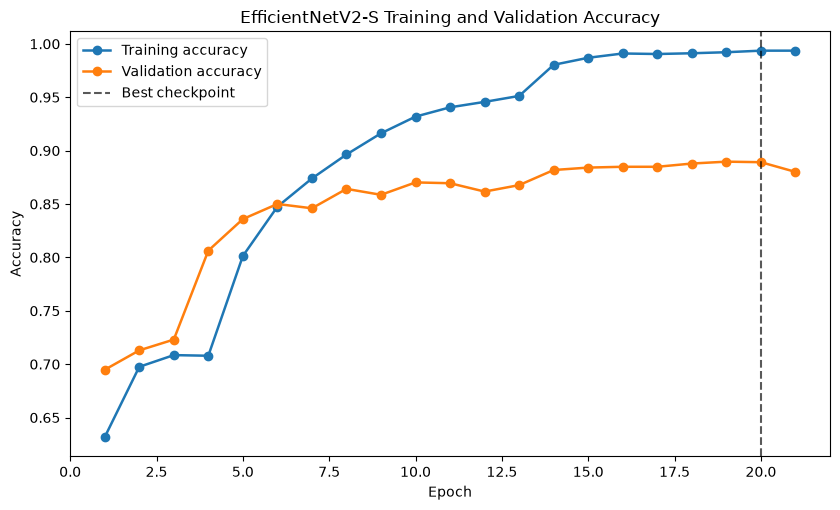

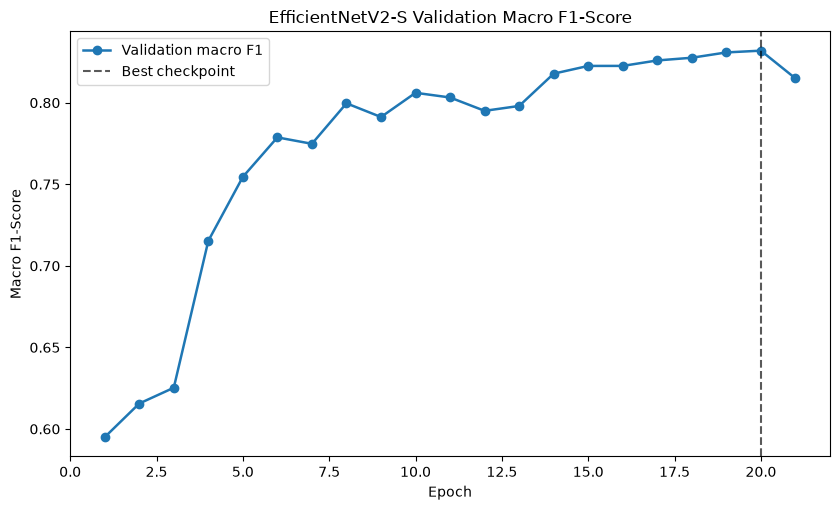

In [11]:
def save_curve(
    history_frame: pd.DataFrame,
    columns: list[str],
    labels: list[str],
    ylabel: str,
    title: str,
    output_path: Path,
):
    fig, ax = plt.subplots(figsize=(8.5, 5.2))
    for column, label in zip(columns, labels):
        ax.plot(
            history_frame["epoch"],
            history_frame[column],
            marker="o",
            linewidth=1.8,
            label=label,
        )
    ax.axvline(best_epoch, color="black", linestyle="--", alpha=0.65, label="Best checkpoint")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend()
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


save_curve(
    training_history,
    ["train_loss", "val_loss"],
    ["Training loss", "Validation loss"],
    "Cross-Entropy Loss",
    "EfficientNetV2-S Training and Validation Loss",
    FIGURES_DIR / "04_efficientnetv2_loss_curve.png",
)
save_curve(
    training_history,
    ["train_accuracy", "val_accuracy"],
    ["Training accuracy", "Validation accuracy"],
    "Accuracy",
    "EfficientNetV2-S Training and Validation Accuracy",
    FIGURES_DIR / "04_efficientnetv2_accuracy_curve.png",
)
save_curve(
    training_history,
    ["val_macro_f1"],
    ["Validation macro F1"],
    "Macro F1-Score",
    "EfficientNetV2-S Validation Macro F1-Score",
    FIGURES_DIR / "04_efficientnetv2_macro_f1_curve.png",
)

## 12. Best-Checkpoint Validation Evaluation

All subsequent analysis reloads the checkpoint selected by validation macro F1 rather than using the final training epoch.

In [12]:
checkpoint = load_model_checkpoint(CHECKPOINT_PATH, model, DEVICE)

if checkpoint["class_mapping"] != CLASS_ID_TO_NAME:
    raise ValueError("The checkpoint class mapping differs from the active manifest mapping.")

best_validation = evaluate_model(
    model,
    validation_loader,
    criterion,
    DEVICE,
    description="Best-checkpoint validation",
)
validation_targets = best_validation["targets"]
validation_predictions = best_validation["predictions"]

validation_metric_values = {
    "accuracy": accuracy_score(validation_targets, validation_predictions),
    "balanced_accuracy": balanced_accuracy_score(
        validation_targets, validation_predictions
    ),
    "macro_f1": f1_score(
        validation_targets, validation_predictions, average="macro", zero_division=0
    ),
    "macro_precision": precision_score(
        validation_targets, validation_predictions, average="macro", zero_division=0
    ),
    "macro_recall": recall_score(
        validation_targets, validation_predictions, average="macro", zero_division=0
    ),
    "weighted_f1": f1_score(
        validation_targets, validation_predictions, average="weighted", zero_division=0
    ),
}
validation_metrics_table = pd.DataFrame(
    {
        "metric": list(validation_metric_values),
        "value": list(validation_metric_values.values()),
    }
)
validation_metrics_table.to_csv(
    REPORTS_DIR / "04_efficientnetv2_validation_metrics.csv",
    index=False,
    encoding="utf-8",
)

class_ids = class_mapping_table["class_id"].to_numpy()
per_class_precision, per_class_recall, per_class_f1, per_class_support = (
    precision_recall_fscore_support(
        validation_targets,
        validation_predictions,
        labels=class_ids,
        zero_division=0,
    )
)
per_class_metrics = pd.DataFrame(
    {
        "class_id": class_ids,
        "class_name": [CLASS_ID_TO_NAME[int(class_id)] for class_id in class_ids],
        "precision": per_class_precision,
        "recall": per_class_recall,
        "f1_score": per_class_f1,
        "support": per_class_support.astype(int),
    }
)
per_class_metrics.to_csv(
    REPORTS_DIR / "04_efficientnetv2_per_class_metrics.csv",
    index=False,
    encoding="utf-8",
)

print(
    f"Loaded best checkpoint from epoch {checkpoint['epoch']} "
    f"({checkpoint['stage']})."
)
display(validation_metrics_table.style.format({"value": "{:.4f}"}))
display(
    per_class_metrics.style.format(
        {
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1_score": "{:.4f}",
            "support": "{:,}",
        }
    )
)

Best-checkpoint validation:   0%|          | 0/496 [00:00<?, ?batch/s]

Loaded best checkpoint from epoch 20 (full_fine_tuning).


,metric,value
0,accuracy,0.8892
1,balanced_accuracy,0.8327
2,macro_f1,0.8319
3,macro_precision,0.8349
4,macro_recall,0.8327
5,weighted_f1,0.8902


,class_id,class_name,precision,recall,f1_score,support
0,0,Eczema,0.7381,0.6798,0.7078,228
1,1,Melanoma,0.9936,0.9958,0.9947,471
2,2,Atopic Dermatitis,0.5365,0.7310,0.6188,171
3,3,Basal Cell Carcinoma (BCC),0.9527,0.9718,0.9622,497
4,4,Melanocytic Nevi (NV),0.9833,0.9858,0.9845,"1,195"
5,5,Benign Keratosis-like Lesions (BKL),0.9189,0.8774,0.8977,310
6,6,Psoriasis / Lichen Planus / Related Diseases,0.7431,0.7329,0.7379,292
7,7,Seborrheic Keratoses / Other Benign Tumors,0.8615,0.8205,0.8405,273
8,8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.8288,0.7510,0.7880,245
9,9,Warts / Molluscum / Other Viral Infections,0.7927,0.7814,0.7870,279


## 13. Confusion Matrices

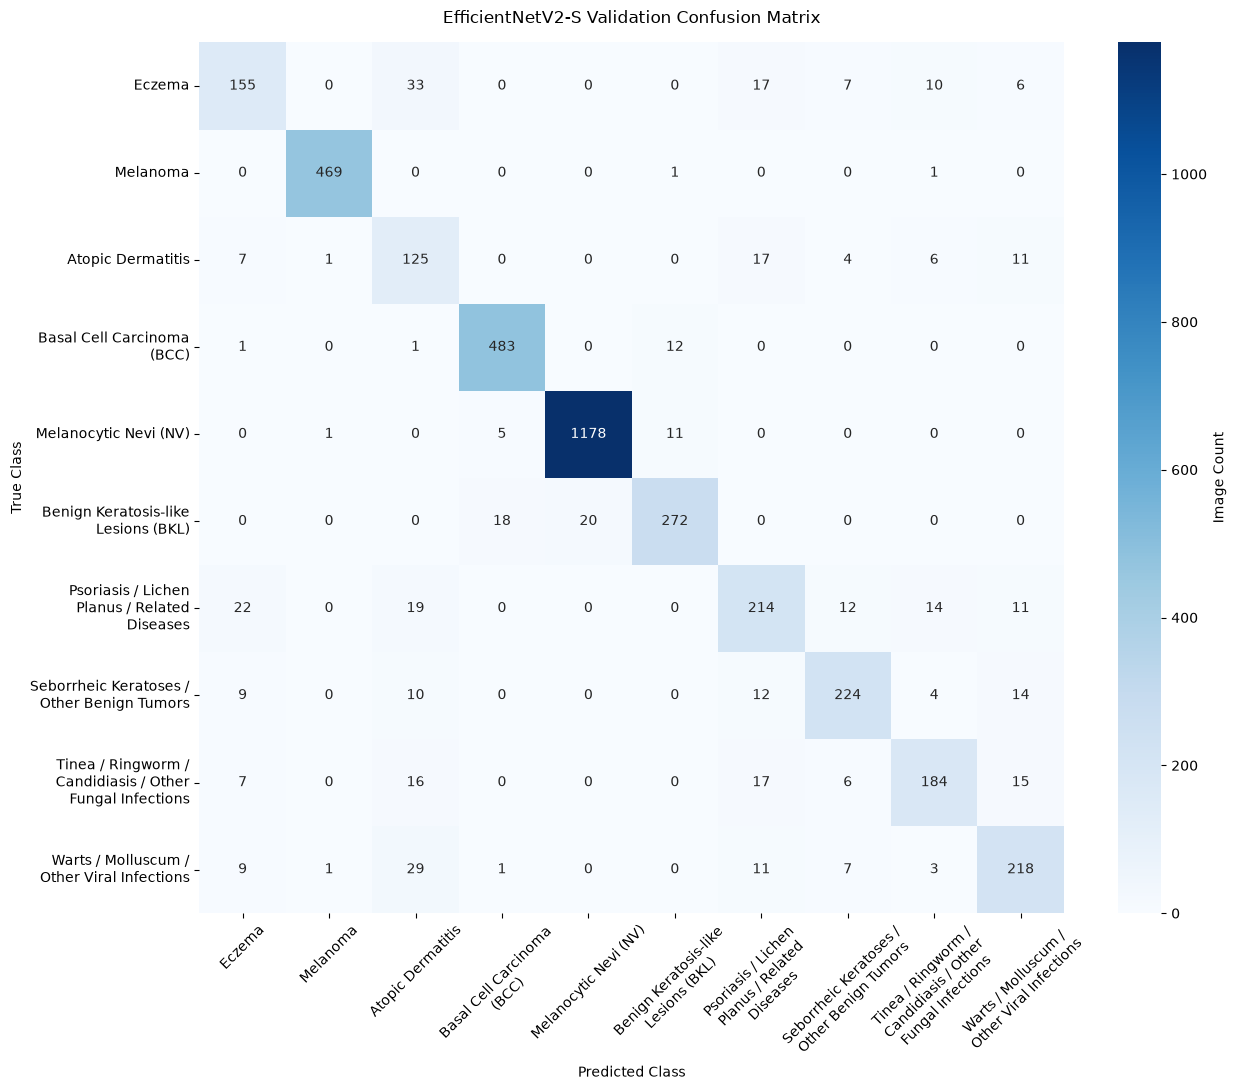

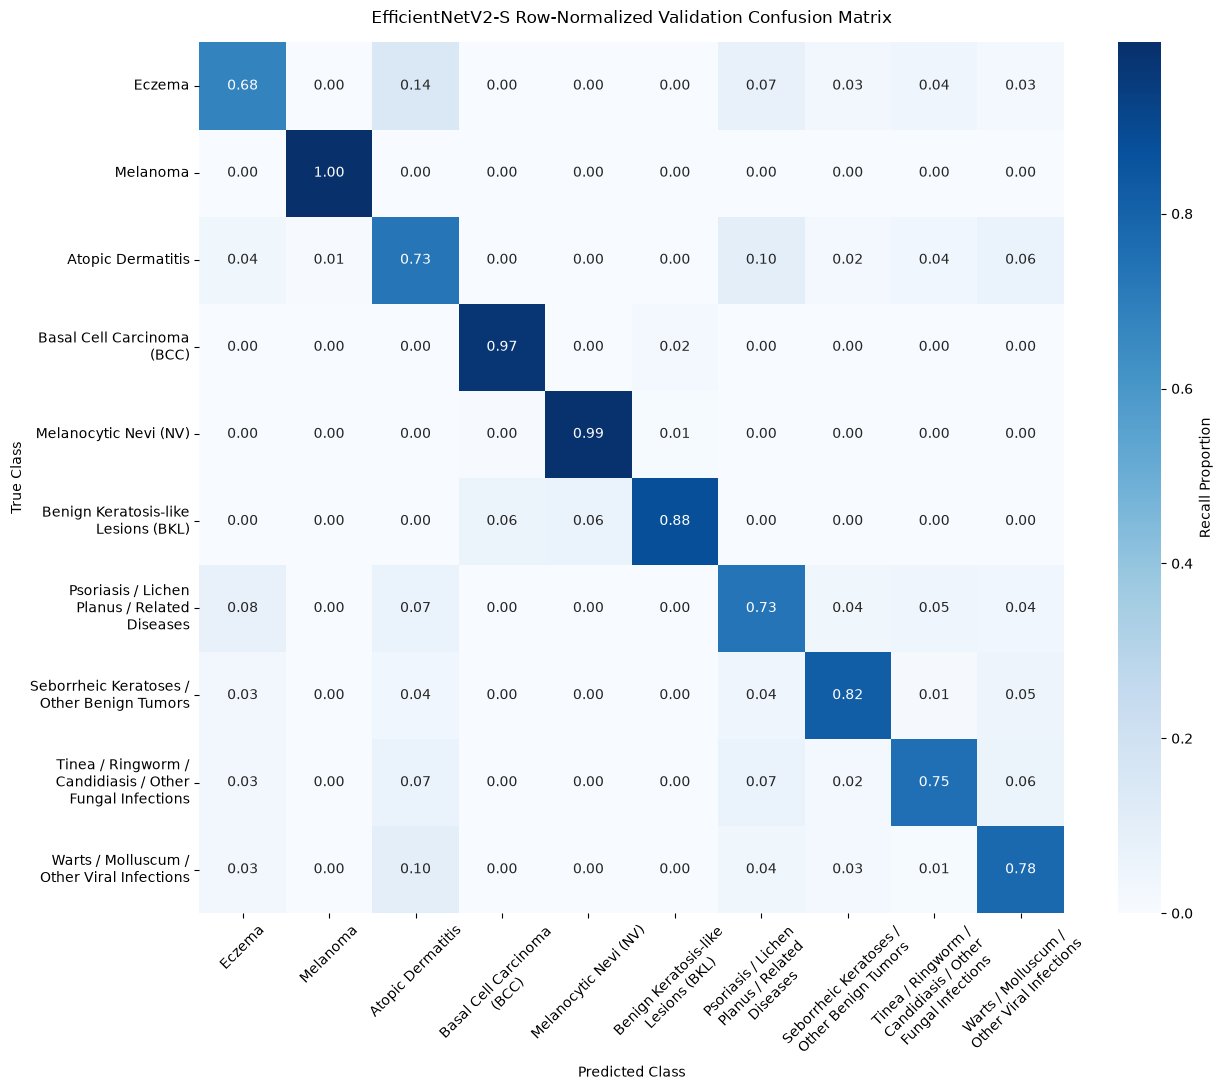

In [13]:
raw_confusion_matrix = confusion_matrix(
    validation_targets, validation_predictions, labels=class_ids
)
normalized_confusion_matrix = confusion_matrix(
    validation_targets,
    validation_predictions,
    labels=class_ids,
    normalize="true",
)
display_labels = [
    textwrap.fill(CLASS_ID_TO_NAME[int(class_id)], width=24) for class_id in class_ids
]


def plot_confusion_matrix(matrix, title, output_path, value_format, colorbar_label):
    fig, ax = plt.subplots(figsize=(13, 11))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=value_format,
        cmap="Blues",
        xticklabels=display_labels,
        yticklabels=display_labels,
        cbar_kws={"label": colorbar_label},
        ax=ax,
    )
    ax.set_title(title, pad=14)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("True Class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
    fig.tight_layout()
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()


plot_confusion_matrix(
    raw_confusion_matrix,
    "EfficientNetV2-S Validation Confusion Matrix",
    FIGURES_DIR / "04_efficientnetv2_confusion_matrix.png",
    "d",
    "Image Count",
)
plot_confusion_matrix(
    normalized_confusion_matrix,
    "EfficientNetV2-S Row-Normalized Validation Confusion Matrix",
    FIGURES_DIR / "04_efficientnetv2_confusion_matrix_normalized.png",
    ".2f",
    "Recall Proportion",
)

## 14. Error Analysis

The analysis below describes observed validation errors without inferring clinical causes.

In [14]:
highest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmax()]
lowest_recall_row = per_class_metrics.loc[per_class_metrics["recall"].idxmin()]
highest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmax()]
lowest_f1_row = per_class_metrics.loc[per_class_metrics["f1_score"].idxmin()]

off_diagonal_confusions = raw_confusion_matrix.copy()
np.fill_diagonal(off_diagonal_confusions, 0)
confusion_records = []
for true_index, predicted_index in zip(
    *np.where(off_diagonal_confusions > 0)
):
    confusion_records.append(
        {
            "true_class": CLASS_ID_TO_NAME[int(class_ids[true_index])],
            "predicted_class": CLASS_ID_TO_NAME[int(class_ids[predicted_index])],
            "image_count": int(off_diagonal_confusions[true_index, predicted_index]),
        }
    )
frequent_confusions = pd.DataFrame(
    confusion_records,
    columns=["true_class", "predicted_class", "image_count"],
).sort_values(
    ["image_count", "true_class", "predicted_class"],
    ascending=[False, True, True],
    ignore_index=True,
)
if frequent_confusions.empty:
    most_common_confusion = {
        "true_class": "none",
        "predicted_class": "none",
        "image_count": 0,
    }
else:
    most_common_confusion = frequent_confusions.iloc[0]

print(
    f"Highest validation recall: {highest_recall_row['class_name']} "
    f"({highest_recall_row['recall']:.4f})"
)
print(
    f"Lowest validation recall: {lowest_recall_row['class_name']} "
    f"({lowest_recall_row['recall']:.4f})"
)
print(
    f"Highest validation F1: {highest_f1_row['class_name']} "
    f"({highest_f1_row['f1_score']:.4f})"
)
print(
    f"Lowest validation F1: {lowest_f1_row['class_name']} "
    f"({lowest_f1_row['f1_score']:.4f})"
)
print("Most frequent directed confusion pairs:")
display(frequent_confusions.head(10))

Highest validation recall: Melanoma (0.9958)
Lowest validation recall: Eczema (0.6798)
Highest validation F1: Melanoma (0.9947)
Lowest validation F1: Atopic Dermatitis (0.6188)
Most frequent directed confusion pairs:


,true_class,predicted_class,image_count
0,Eczema,Atopic Dermatitis,33
1,Warts / Molluscum / Other Viral Infections,Atopic Dermatitis,29
2,Psoriasis / Lichen Planus / Related Diseases,Eczema,22
3,Benign Keratosis-like Lesions (BKL),Melanocytic Nevi (NV),20
4,Psoriasis / Lichen Planus / Related Diseases,Atopic Dermatitis,19
5,Benign Keratosis-like Lesions (BKL),Basal Cell Carcinoma (BCC),18
6,Atopic Dermatitis,Psoriasis / Lichen Planus / Related Diseases,17
7,Eczema,Psoriasis / Lichen Planus / Related Diseases,17
8,Tinea / Ringworm / Candidiasis / Other Fungal ...,Psoriasis / Lichen Planus / Related Diseases,17
9,Tinea / Ringworm / Candidiasis / Other Fungal ...,Atopic Dermatitis,16


## 15. Confidence Analysis

Softmax confidence is summarized separately for correct and incorrect validation predictions. These values describe the model output distribution and are not a calibration assessment.

Average confidence for correct predictions: 0.9813
Average confidence for incorrect predictions: 0.8318


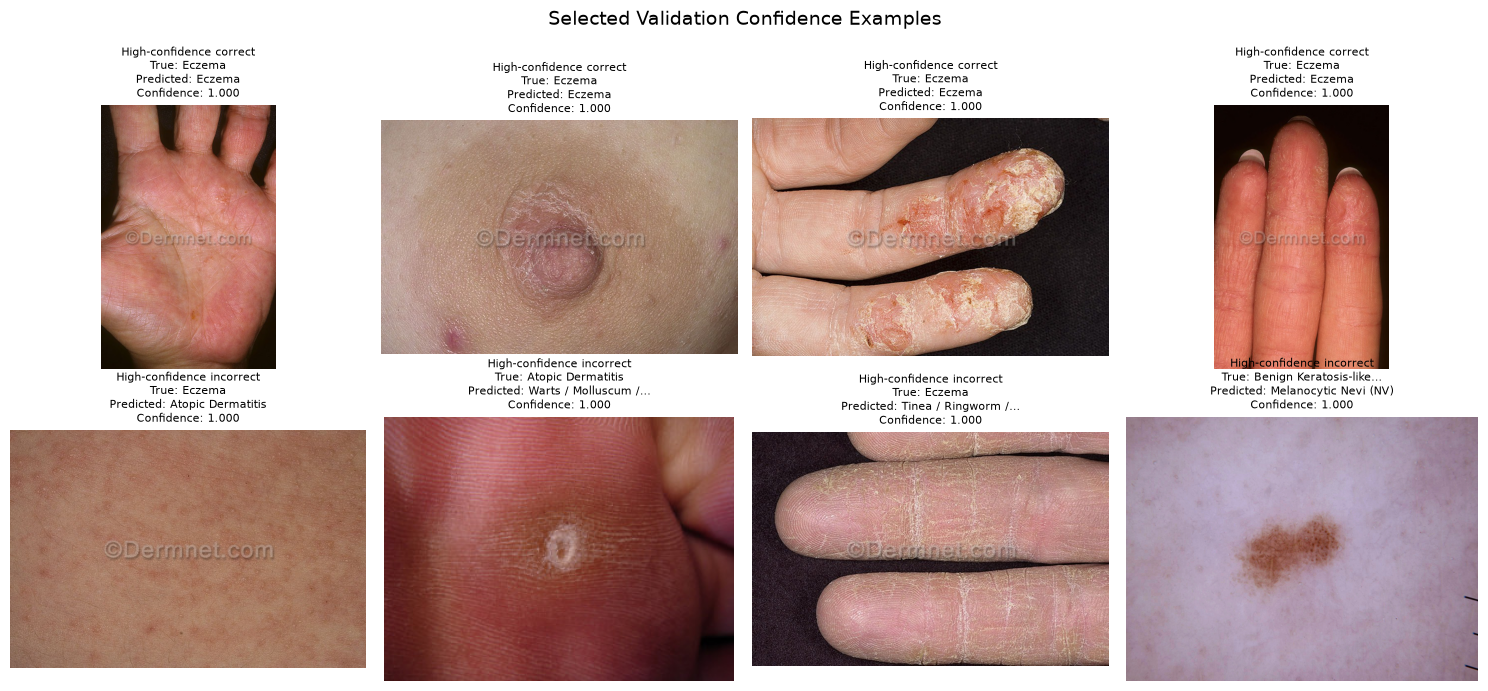

In [15]:
validation_predictions_table = pd.DataFrame(
    {
        "relative_path": best_validation["relative_paths"],
        "true_class_id": validation_targets,
        "predicted_class_id": validation_predictions,
        "confidence": best_validation["confidences"],
    }
)
validation_predictions_table["correct"] = (
    validation_predictions_table["true_class_id"]
    == validation_predictions_table["predicted_class_id"]
)
validation_predictions_table["true_class"] = validation_predictions_table[
    "true_class_id"
].map(CLASS_ID_TO_NAME)
validation_predictions_table["predicted_class"] = validation_predictions_table[
    "predicted_class_id"
].map(CLASS_ID_TO_NAME)

correct_confidence = validation_predictions_table.loc[
    validation_predictions_table["correct"], "confidence"
].mean()
incorrect_confidence = validation_predictions_table.loc[
    ~validation_predictions_table["correct"], "confidence"
].mean()

print(f"Average confidence for correct predictions: {correct_confidence:.4f}")
print(f"Average confidence for incorrect predictions: {incorrect_confidence:.4f}")

confidence_examples = pd.concat(
    [
        validation_predictions_table.loc[validation_predictions_table["correct"]]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence correct"),
        validation_predictions_table.loc[~validation_predictions_table["correct"]]
        .nlargest(4, "confidence")
        .assign(example_type="High-confidence incorrect"),
    ],
    ignore_index=True,
)

fig, axes = plt.subplots(2, 4, figsize=(15, 7), squeeze=False)
for axis, (_, row) in zip(axes.flat, confidence_examples.iterrows()):
    with Image.open(PROJECT_ROOT / row["relative_path"]) as image:
        image_for_display = ImageOps.exif_transpose(image).convert("RGB")
        axis.imshow(image_for_display)
    axis.set_title(
        f"{row['example_type']}\n"
        f"True: {textwrap.shorten(row['true_class'], 24, placeholder='…')}\n"
        f"Predicted: {textwrap.shorten(row['predicted_class'], 24, placeholder='…')}\n"
        f"Confidence: {row['confidence']:.3f}",
        fontsize=8,
    )
    axis.axis("off")
for axis in axes.flat[len(confidence_examples):]:
    axis.axis("off")
fig.suptitle("Selected Validation Confidence Examples", fontsize=14)
fig.tight_layout()
plt.show()

## 16. Overfitting and Generalization Analysis

The training-validation accuracy gap, per-class F1 range, and support-F1 association are descriptive indicators. They do not by themselves establish overfitting mechanisms or a causal effect of class frequency.

In [16]:
selected_history = training_history.loc[
    training_history["epoch"] == checkpoint["epoch"]
]
if len(selected_history) != 1:
    raise ValueError("The selected checkpoint epoch is not unique in the training history.")

best_history_row = selected_history.iloc[0]
first_history_row = training_history.iloc[0]
last_history_row = training_history.iloc[-1]
minimum_validation_loss_row = training_history.loc[
    training_history["val_loss"].idxmin()
]

training_validation_gap = (
    best_history_row["train_accuracy"] - validation_metric_values["accuracy"]
)
per_class_f1_range = (
    per_class_metrics["f1_score"].max() - per_class_metrics["f1_score"].min()
)
support_f1_spearman = per_class_metrics["support"].corr(
    per_class_metrics["f1_score"], method="spearman"
)

generalization_indicators = pd.DataFrame(
    {
        "indicator": [
            "Training-validation accuracy gap at selected checkpoint",
            "Per-class F1 range",
            "Spearman correlation: validation support vs. F1",
        ],
        "value": [
            training_validation_gap,
            per_class_f1_range,
            support_f1_spearman,
        ],
    }
)
display(generalization_indicators.style.format({"value": "{:.4f}"}))

,indicator,value
0,Training-validation accuracy gap at selected checkpoint,0.1044
1,Per-class F1 range,0.3759
2,Spearman correlation: validation support vs. F1,0.8545


## 17. Direct Comparison with ResNet50

The saved ResNet50 validation reports are loaded rather than transcribed. Differences are defined as EfficientNetV2-S minus ResNet50. A single validation split supports descriptive comparison but not a claim of statistical significance.

,Metric,ResNet50,EfficientNetV2-S,Absolute Difference
0,accuracy,0.8533,0.8892,+0.0358
1,balanced_accuracy,0.7885,0.8327,+0.0442
2,macro_f1,0.7869,0.8319,+0.0450
3,macro_precision,0.7869,0.8349,+0.0480
4,macro_recall,0.7885,0.8327,+0.0442
5,weighted_f1,0.8533,0.8902,+0.0369


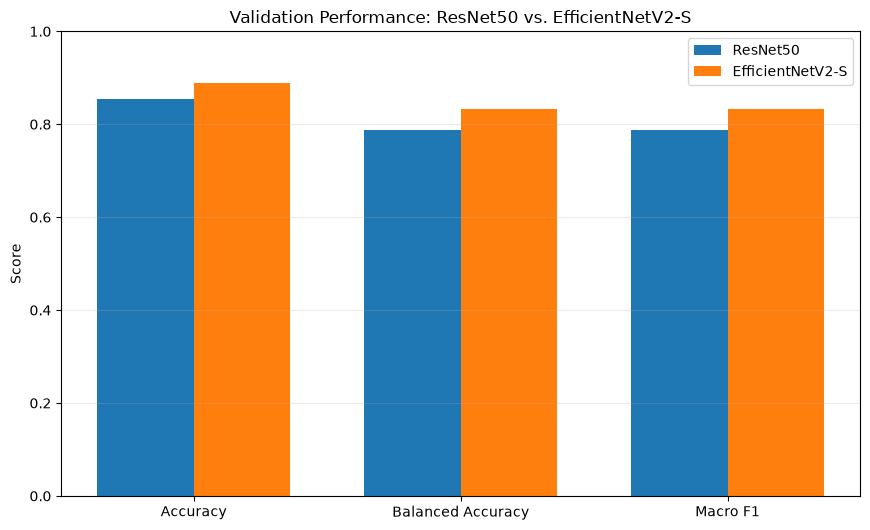

In [17]:
RESNET50_VALIDATION_METRICS_PATH = REPORTS_DIR / "03_resnet50_validation_metrics.csv"
RESNET50_PER_CLASS_METRICS_PATH = REPORTS_DIR / "03_resnet50_per_class_metrics.csv"
RESNET50_TRAINING_HISTORY_PATH = REPORTS_DIR / "03_resnet50_training_history.csv"

required_resnet50_files = [
    RESNET50_VALIDATION_METRICS_PATH,
    RESNET50_PER_CLASS_METRICS_PATH,
    RESNET50_TRAINING_HISTORY_PATH,
]
missing_resnet50_files = [
    path for path in required_resnet50_files if not path.is_file()
]
if missing_resnet50_files:
    missing_text = "\n".join(f"  - {path}" for path in missing_resnet50_files)
    raise FileNotFoundError(
        "The saved ResNet50 reports required for comparison are missing:\n"
        f"{missing_text}"
    )

resnet50_validation_metrics = pd.read_csv(RESNET50_VALIDATION_METRICS_PATH)
expected_overall_columns = {"metric", "value"}
if set(resnet50_validation_metrics.columns) != expected_overall_columns:
    raise ValueError(
        "03_resnet50_validation_metrics.csv must contain exactly: metric, value."
    )
if resnet50_validation_metrics["metric"].duplicated().any():
    raise ValueError("The ResNet50 validation report contains duplicate metrics.")

comparison_metrics = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "macro_precision",
    "macro_recall",
    "weighted_f1",
]
resnet50_metric_values = (
    resnet50_validation_metrics.set_index("metric")["value"].astype(float)
)
missing_comparison_metrics = [
    metric for metric in comparison_metrics if metric not in resnet50_metric_values.index
]
if missing_comparison_metrics:
    raise ValueError(
        "The ResNet50 validation report is missing metrics: "
        f"{missing_comparison_metrics}"
    )

overall_comparison = pd.DataFrame(
    {
        "Metric": comparison_metrics,
        "ResNet50": [resnet50_metric_values[metric] for metric in comparison_metrics],
        "EfficientNetV2-S": [
            validation_metric_values[metric] for metric in comparison_metrics
        ],
    }
)
overall_comparison["Absolute Difference"] = (
    overall_comparison["EfficientNetV2-S"] - overall_comparison["ResNet50"]
)
overall_comparison.to_csv(
    REPORTS_DIR / "04_resnet50_vs_efficientnetv2.csv",
    index=False,
    encoding="utf-8",
)
display(
    overall_comparison.style.format(
        {
            "ResNet50": "{:.4f}",
            "EfficientNetV2-S": "{:.4f}",
            "Absolute Difference": "{:+.4f}",
        }
    )
)

main_comparison = overall_comparison.loc[
    overall_comparison["Metric"].isin(
        ["accuracy", "balanced_accuracy", "macro_f1"]
    )
].copy()
metric_labels = ["Accuracy", "Balanced Accuracy", "Macro F1"]
x_positions = np.arange(len(main_comparison))
bar_width = 0.36

fig, ax = plt.subplots(figsize=(8.8, 5.4))
ax.bar(
    x_positions - bar_width / 2,
    main_comparison["ResNet50"],
    width=bar_width,
    label="ResNet50",
)
ax.bar(
    x_positions + bar_width / 2,
    main_comparison["EfficientNetV2-S"],
    width=bar_width,
    label="EfficientNetV2-S",
)
ax.set_xticks(x_positions, metric_labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Validation Performance: ResNet50 vs. EfficientNetV2-S")
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "04_resnet50_vs_efficientnetv2.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 18. Per-Class Comparison

,class_name,resnet50_f1,efficientnetv2_f1,f1_difference
8,Tinea / Ringworm / Candidiasis / Other Fungal Infections,0.6851,0.7880,+0.1029
9,Warts / Molluscum / Other Viral Infections,0.6932,0.7870,+0.0938
6,Psoriasis / Lichen Planus / Related Diseases,0.6542,0.7379,+0.0837
7,Seborrheic Keratoses / Other Benign Tumors,0.7700,0.8405,+0.0705
5,Benign Keratosis-like Lesions (BKL),0.8357,0.8977,+0.0620
3,Basal Cell Carcinoma (BCC),0.9388,0.9622,+0.0233
4,Melanocytic Nevi (NV),0.9694,0.9845,+0.0152
0,Eczema,0.7009,0.7078,+0.0069
1,Melanoma,0.9882,0.9947,+0.0065
2,Atopic Dermatitis,0.6331,0.6188,-0.0142


Classes with improved F1: 9
Classes with lower F1: 1
Classes with unchanged F1: 0
Largest class-level F1 improvement: Tinea / Ringworm / Candidiasis / Other Fungal Infections (+0.1029)
Largest class-level F1 decrease: Atopic Dermatitis (-0.0142)


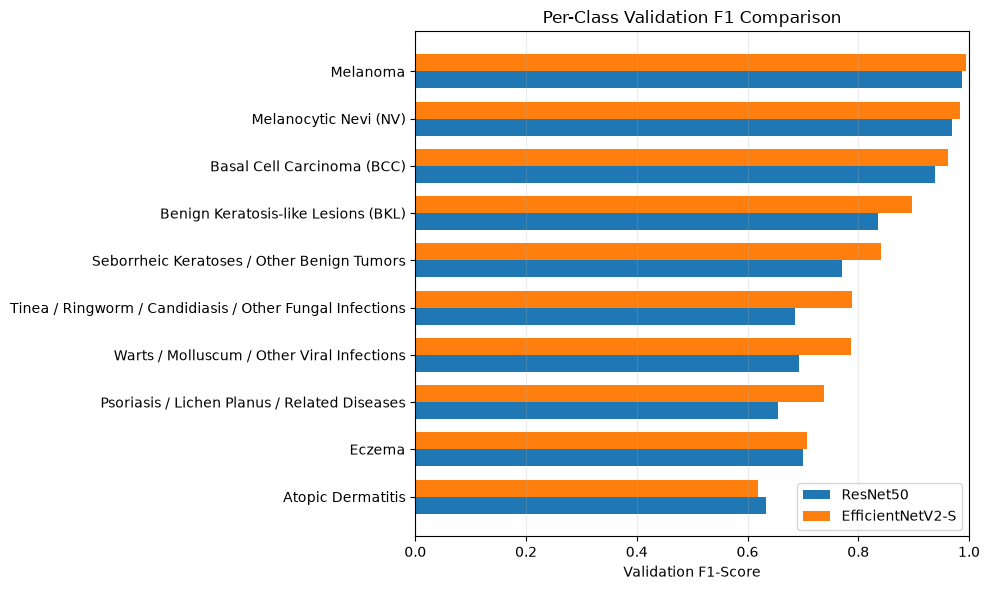

In [18]:
resnet50_per_class_metrics = pd.read_csv(RESNET50_PER_CLASS_METRICS_PATH)
expected_per_class_columns = {
    "class_id",
    "class_name",
    "precision",
    "recall",
    "f1_score",
    "support",
}
if set(resnet50_per_class_metrics.columns) != expected_per_class_columns:
    raise ValueError(
        "03_resnet50_per_class_metrics.csv has an unexpected schema."
    )
if resnet50_per_class_metrics[["class_id", "class_name"]].duplicated().any():
    raise ValueError("The ResNet50 per-class report contains duplicate classes.")

per_class_comparison_full = resnet50_per_class_metrics.merge(
    per_class_metrics,
    on=["class_id", "class_name"],
    how="inner",
    suffixes=("_resnet50", "_efficientnetv2"),
    validate="one_to_one",
)
if len(per_class_comparison_full) != NUM_CLASSES:
    raise ValueError(
        "The ResNet50 and EfficientNetV2-S per-class reports do not share the full "
        "active class mapping."
    )

per_class_comparison = per_class_comparison_full[
    ["class_name", "f1_score_resnet50", "f1_score_efficientnetv2"]
].rename(
    columns={
        "f1_score_resnet50": "resnet50_f1",
        "f1_score_efficientnetv2": "efficientnetv2_f1",
    }
)
per_class_comparison["f1_difference"] = (
    per_class_comparison["efficientnetv2_f1"]
    - per_class_comparison["resnet50_f1"]
)
per_class_comparison.to_csv(
    REPORTS_DIR / "04_resnet50_vs_efficientnetv2_per_class.csv",
    index=False,
    encoding="utf-8",
)

classes_improved = int((per_class_comparison["f1_difference"] > 0).sum())
classes_worsened = int((per_class_comparison["f1_difference"] < 0).sum())
classes_unchanged = int((per_class_comparison["f1_difference"] == 0).sum())
if classes_improved > 0:
    largest_improvement_row = per_class_comparison.loc[
        per_class_comparison["f1_difference"].idxmax()
    ]
    largest_improvement_text = (
        f"{largest_improvement_row['class_name']} "
        f"({largest_improvement_row['f1_difference']:+.4f})"
    )
else:
    largest_improvement_text = "No class-level F1 improvement was observed."

if classes_worsened > 0:
    largest_decrease_row = per_class_comparison.loc[
        per_class_comparison["f1_difference"].idxmin()
    ]
    largest_decrease_text = (
        f"{largest_decrease_row['class_name']} "
        f"({largest_decrease_row['f1_difference']:+.4f})"
    )
else:
    largest_decrease_text = "No class-level F1 decrease was observed."

display(
    per_class_comparison.sort_values("f1_difference", ascending=False).style.format(
        {
            "resnet50_f1": "{:.4f}",
            "efficientnetv2_f1": "{:.4f}",
            "f1_difference": "{:+.4f}",
        }
    )
)
print(f"Classes with improved F1: {classes_improved}")
print(f"Classes with lower F1: {classes_worsened}")
print(f"Classes with unchanged F1: {classes_unchanged}")
print(f"Largest class-level F1 improvement: {largest_improvement_text}")
print(f"Largest class-level F1 decrease: {largest_decrease_text}")

per_class_plot = per_class_comparison.sort_values(
    "efficientnetv2_f1", ascending=True
).reset_index(drop=True)
y_positions = np.arange(len(per_class_plot))

fig, ax = plt.subplots(
    figsize=(10, max(6, 0.48 * len(per_class_plot)))
)
ax.barh(
    y_positions - bar_width / 2,
    per_class_plot["resnet50_f1"],
    height=bar_width,
    label="ResNet50",
)
ax.barh(
    y_positions + bar_width / 2,
    per_class_plot["efficientnetv2_f1"],
    height=bar_width,
    label="EfficientNetV2-S",
)
ax.set_yticks(y_positions, per_class_plot["class_name"])
ax.set_xlim(0, 1)
ax.set_xlabel("Validation F1-Score")
ax.set_title("Per-Class Validation F1 Comparison")
ax.legend()
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "04_resnet50_vs_efficientnetv2_per_class_f1.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## 19. ResNet50 Generalization-Gap Reference

In [19]:
resnet50_training_history = pd.read_csv(RESNET50_TRAINING_HISTORY_PATH)
required_history_columns = {
    "epoch",
    "train_accuracy",
    "val_accuracy",
    "val_macro_f1",
}
missing_history_columns = required_history_columns - set(
    resnet50_training_history.columns
)
if missing_history_columns:
    raise ValueError(
        "03_resnet50_training_history.csv is missing columns: "
        f"{sorted(missing_history_columns)}"
    )

resnet50_selected_history = resnet50_training_history.loc[
    resnet50_training_history["val_macro_f1"].idxmax()
]
resnet50_training_validation_gap = (
    float(resnet50_selected_history["train_accuracy"])
    - float(resnet50_metric_values["accuracy"])
)
gap_difference = training_validation_gap - resnet50_training_validation_gap

gap_comparison = pd.DataFrame(
    {
        "Architecture": ["ResNet50", "EfficientNetV2-S"],
        "Selected Epoch": [
            int(resnet50_selected_history["epoch"]),
            int(checkpoint["epoch"]),
        ],
        "Training-Validation Accuracy Gap": [
            resnet50_training_validation_gap,
            training_validation_gap,
        ],
    }
)
display(
    gap_comparison.style.format(
        {"Training-Validation Accuracy Gap": "{:+.4f}"}
    )
)

,Architecture,Selected Epoch,Training-Validation Accuracy Gap
0,ResNet50,19,+0.1294
1,EfficientNetV2-S,20,+0.1044


## 20. Test Set Policy

The test manifest was checked only for schema, class mapping, path uniqueness, file existence, and size. No test dataset loader, predictions, accuracy, F1-score, or confusion matrix are produced. The test subset remains frozen until architecture selection and model-development decisions are complete.

## EfficientNetV2-S Baseline Summary

In [20]:
summary_markdown = f"""
- **Best checkpoint epoch:** {checkpoint['epoch']} ({checkpoint['stage'].replace('_', ' ')})
- **Validation accuracy:** {validation_metric_values['accuracy']:.4f}
- **Validation balanced accuracy:** {validation_metric_values['balanced_accuracy']:.4f}
- **Validation macro F1:** {validation_metric_values['macro_f1']:.4f}
- **Validation macro precision:** {validation_metric_values['macro_precision']:.4f}
- **Validation macro recall:** {validation_metric_values['macro_recall']:.4f}
- **Strongest class by validation F1:** {highest_f1_row['class_name']} ({highest_f1_row['f1_score']:.4f})
- **Weakest class by validation F1:** {lowest_f1_row['class_name']} ({lowest_f1_row['f1_score']:.4f})
- **Most common directed confusion:** true {most_common_confusion['true_class']} predicted as {most_common_confusion['predicted_class']} ({int(most_common_confusion['image_count'])} images)
- **Training-validation accuracy gap:** {training_validation_gap:+.4f}
"""
display(Markdown(summary_markdown))


- **Best checkpoint epoch:** 20 (full fine tuning)
- **Validation accuracy:** 0.8892
- **Validation balanced accuracy:** 0.8327
- **Validation macro F1:** 0.8319
- **Validation macro precision:** 0.8349
- **Validation macro recall:** 0.8327
- **Strongest class by validation F1:** Melanoma (0.9947)
- **Weakest class by validation F1:** Atopic Dermatitis (0.6188)
- **Most common directed confusion:** true Eczema predicted as Atopic Dermatitis (33 images)
- **Training-validation accuracy gap:** +0.1044


### Comparison with ResNet50

In [21]:
overall_difference_by_metric = overall_comparison.set_index("Metric")[
    "Absolute Difference"
]
accuracy_difference = overall_difference_by_metric["accuracy"]
balanced_accuracy_difference = overall_difference_by_metric["balanced_accuracy"]
macro_f1_difference = overall_difference_by_metric["macro_f1"]


def describe_signed_difference(value: float) -> str:
    if value > 0:
        return f"higher by {value:.4f}"
    if value < 0:
        return f"lower by {abs(value):.4f}"
    return "unchanged"


if gap_difference > 0:
    gap_comparison_text = (
        f"The training-validation accuracy gap increased by {gap_difference:.4f}."
    )
elif gap_difference < 0:
    gap_comparison_text = (
        f"The training-validation accuracy gap decreased by {abs(gap_difference):.4f}."
    )
else:
    gap_comparison_text = "The training-validation accuracy gap was unchanged."

comparison_summary_markdown = f"""
Relative to the saved ResNet50 baseline, EfficientNetV2-S validation accuracy was {describe_signed_difference(accuracy_difference)}, balanced accuracy was {describe_signed_difference(balanced_accuracy_difference)}, and macro F1 was {describe_signed_difference(macro_f1_difference)}.

Per-class F1 improved for {classes_improved} classes and decreased for {classes_worsened} classes. Largest improvement: **{largest_improvement_text}** Largest decrease: **{largest_decrease_text}** {gap_comparison_text}

These differences describe one fixed validation split and do not establish statistical significance or definitive architectural superiority.
"""
display(Markdown(comparison_summary_markdown))


Relative to the saved ResNet50 baseline, EfficientNetV2-S validation accuracy was higher by 0.0358, balanced accuracy was higher by 0.0442, and macro F1 was higher by 0.0450.

Per-class F1 improved for 9 classes and decreased for 1 classes. Largest improvement: **Tinea / Ringworm / Candidiasis / Other Fungal Infections (+0.1029)** Largest decrease: **Atopic Dermatitis (-0.0142)** The training-validation accuracy gap decreased by 0.0250.

These differences describe one fixed validation split and do not establish statistical significance or definitive architectural superiority.


### Interpretation

In [22]:
if training_validation_gap > 0.10:
    fit_interpretation = (
        "The training-validation accuracy gap at the selected epoch is notable and is "
        "compatible with overfitting, although validation-selected checkpointing limits "
        "the effect on the reported baseline."
    )
elif training_validation_gap > 0.03:
    fit_interpretation = (
        "A modest training-validation accuracy gap is present at the selected epoch, "
        "indicating some overfitting pressure."
    )
else:
    fit_interpretation = (
        "The selected epoch does not show a large training-validation accuracy gap, so "
        "the recorded curves provide no strong evidence of overfitting at that point."
    )

if support_f1_spearman > 0.30:
    imbalance_interpretation = (
        "Per-class support and F1 show a positive rank association, consistent with class "
        "frequency contributing to uneven performance; this association does not establish causation."
    )
elif support_f1_spearman < -0.30:
    imbalance_interpretation = (
        "Per-class support and F1 show a negative rank association in this validation result, "
        "so class frequency alone does not explain the observed class-level differences."
    )
else:
    imbalance_interpretation = (
        "The rank association between per-class support and F1 is weak; class imbalance alone "
        "does not explain the observed class-level differences."
    )

if (
    last_history_row["epoch"] > minimum_validation_loss_row["epoch"]
    and last_history_row["val_loss"] > minimum_validation_loss_row["val_loss"]
):
    validation_loss_interpretation = (
        f"Validation loss reached its minimum of "
        f"{minimum_validation_loss_row['val_loss']:.4f} at epoch "
        f"{int(minimum_validation_loss_row['epoch'])} and ended at "
        f"{last_history_row['val_loss']:.4f}, indicating deterioration after the "
        "minimum-loss epoch."
    )
else:
    validation_loss_interpretation = (
        f"The minimum validation loss was {minimum_validation_loss_row['val_loss']:.4f} "
        f"at epoch {int(minimum_validation_loss_row['epoch'])}; the final recorded "
        f"validation loss was {last_history_row['val_loss']:.4f}."
    )

if checkpoint["epoch"] < last_history_row["epoch"]:
    macro_f1_interpretation = (
        f"Validation macro F1 peaked at {validation_metric_values['macro_f1']:.4f} "
        f"at the selected epoch and was {last_history_row['val_macro_f1']:.4f} "
        "in the final completed epoch."
    )
else:
    macro_f1_interpretation = (
        f"The selected final epoch reached validation macro F1 "
        f"{validation_metric_values['macro_f1']:.4f}."
    )

interpretation_markdown = f"""
Validation macro F1 changed from {first_history_row['val_macro_f1']:.4f} in the first warm-up epoch to the checkpoint-selected value of {validation_metric_values['macro_f1']:.4f} at epoch {checkpoint['epoch']}. {macro_f1_interpretation} {validation_loss_interpretation}

At the selected epoch, training accuracy was {best_history_row['train_accuracy']:.4f} and validation accuracy was {validation_metric_values['accuracy']:.4f}, a difference of {training_validation_gap:+.4f}. {fit_interpretation}

Per-class F1 spans {per_class_f1_range:.4f}, while the Spearman association between validation support and per-class F1 is {support_f1_spearman:.3f}. {imbalance_interpretation} The most frequent directed confusion was true **{most_common_confusion['true_class']}** predicted as **{most_common_confusion['predicted_class']}** ({int(most_common_confusion['image_count'])} images). These patterns describe the validation subset and do not justify unsupported medical explanations.

The controlled comparison is limited by heterogeneous image sources, different acquisition styles, DermNet watermarks, other possible shortcut-learning cues, and the lack of universal patient-level identifiers. The fixed split reduces leakage from detected duplicate groups but cannot guarantee patient-level independence for all images. Neither validation performance nor softmax confidence establishes calibration, external generalization, or clinical diagnostic reliability.
"""
display(Markdown(interpretation_markdown))


Validation macro F1 changed from 0.5950 in the first warm-up epoch to the checkpoint-selected value of 0.8319 at epoch 20. Validation macro F1 peaked at 0.8319 at the selected epoch and was 0.8149 in the final completed epoch. Validation loss reached its minimum of 0.4240 at epoch 6 and ended at 0.6114, indicating deterioration after the minimum-loss epoch.

At the selected epoch, training accuracy was 0.9936 and validation accuracy was 0.8892, a difference of +0.1044. The training-validation accuracy gap at the selected epoch is notable and is compatible with overfitting, although validation-selected checkpointing limits the effect on the reported baseline.

Per-class F1 spans 0.3759, while the Spearman association between validation support and per-class F1 is 0.855. Per-class support and F1 show a positive rank association, consistent with class frequency contributing to uneven performance; this association does not establish causation. The most frequent directed confusion was true **Eczema** predicted as **Atopic Dermatitis** (33 images). These patterns describe the validation subset and do not justify unsupported medical explanations.

The controlled comparison is limited by heterogeneous image sources, different acquisition styles, DermNet watermarks, other possible shortcut-learning cues, and the lack of universal patient-level identifiers. The fixed split reduces leakage from detected duplicate groups but cannot guarantee patient-level independence for all images. Neither validation performance nor softmax confidence establishes calibration, external generalization, or clinical diagnostic reliability.


### Next Steps

The next controlled architecture experiment may evaluate ConvNeXt-Tiny while retaining the same frozen split and evaluation policy. Architecture baselines should be compared before introducing class weighting, MixUp, CutMix, focal loss, Grad-CAM, or extensive hyperparameter tuning; those extensions remain outside this notebook.

## Reproducibility Summary

In [23]:
configuration_summary = pd.DataFrame(
    {
        "Configuration Item": list(TRAINING_CONFIGURATION),
        "Value": list(TRAINING_CONFIGURATION.values()),
    }
)
display(configuration_summary)
print(f"Completed epochs: {len(training_history)}")
print(f"Best checkpoint path: {CHECKPOINT_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print("Test-set predictions generated: False")

,Configuration Item,Value
0,random_seed,42
1,architecture,EfficientNetV2-S
2,pretrained_weights,IMAGENET1K_V1
3,image_size,384
4,batch_size,8
5,optimizer,AdamW
6,warmup_learning_rate,0.001
7,fine_tune_learning_rate,0.0001
8,weight_decay,0.0001
9,warmup_epochs,3


Completed epochs: 21
Best checkpoint path: models/efficientnetv2_s_baseline_best.pth
Test-set predictions generated: False
